# ⏱️ Monte Carlo × Diferença Temporal: esperar o fim ou ajustar no caminho?

Os dois métodos aprendem **sem modelo** — só jogando. A diferença é **quando** cada um corrige as suas estimativas (slides 79–81):

| | Monte Carlo (slide 79) | Diferença Temporal (slide 81) |
|---|---|---|
| Quando atualiza | no **fim** do episódio | a **cada passo** |
| Alvo | o retorno real $G$ | $R + \gamma\,V(s')$ — a recompensa + a estimativa do próximo estado |
| Analogia | dar nota ao restaurante só depois de comer | ajustar a previsão da viagem a cada esquina |

**Roteiro**
1. **A volta para casa:** as duas regras numa viagem só, passo a passo.
2. **O passeio na avenida:** os dois aprendendo de verdade, lado a lado.
3. **A corrida:** quem erra menos, e mais rápido?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML
import ipywidgets as widgets

## 1. A volta para casa (a analogia do slide 81)

Você sai do trabalho prevendo **40 minutos** de viagem. Em cada ponto do caminho, olha o relógio e refaz a previsão de quanto falta:

| Ponto da viagem | Minutos decorridos | Previsão de quanto falta | Previsão do total |
|---|---|---|---|
| Saindo do escritório | 0 | 40 | 40 |
| 1ª esquina: trânsito! | 10 | 40 | 50 |
| Entrou na marginal, fluindo | 25 | 15 | 40 |
| Acidente na saída da marginal | 35 | 15 | 50 |
| Rua de casa | 48 | 4 | 52 |
| **Chegou** | **52** | 0 | **52** |

A pergunta de RL: **como corrigir a previsão feita em cada ponto?**

- **Monte Carlo** espera chegar em casa. Só então compara cada previsão com o total **real** (52 min) e corrige todas.
- **Diferença Temporal** corrige cada previsão **já no ponto seguinte**, usando a nova previsão como alvo: "achei 40, mas uma esquina depois já parece 50".

> **Palpite:** na 1ª esquina, para quanto o TD puxa a previsão de "Saindo do escritório"? E o Monte Carlo?

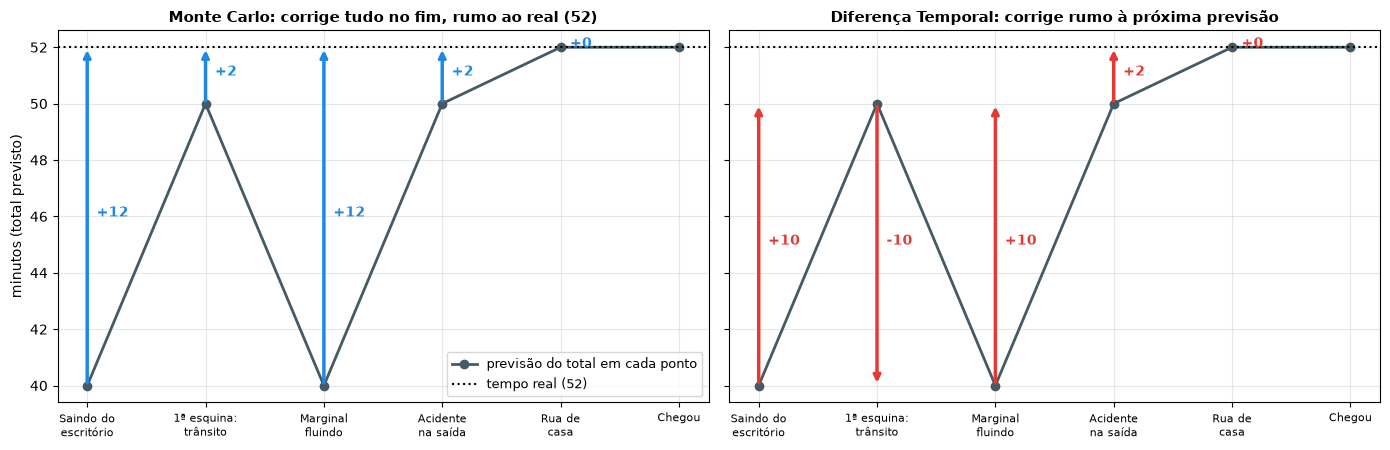

Correção sugerida em cada ponto (alvo − previsão):
ponto                             Monte Carlo     TD
Saindo do escritório                      +12    +10
1ª esquina: trânsito                       +2    -10
Marginal fluindo                          +12    +10
Acidente na saída                          +2     +2
Rua de casa                                +0     +0


In [2]:
pontos = ['Saindo do\nescritório', '1ª esquina:\ntrânsito', 'Marginal\nfluindo', 'Acidente\nna saída', 'Rua de\ncasa', 'Chegou']
previsao_total = np.array([40, 50, 40, 50, 52, 52])   # decorrido + previsão de quanto falta
real = 52

alvo_mc = np.full(5, real)                     # MC: o resultado final, para todos
alvo_td = previsao_total[1:]                   # TD: a previsão do ponto seguinte

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, alvo, titulo, cor in [(axes[0], alvo_mc, 'Monte Carlo: corrige tudo no fim, rumo ao real (52)', '#1E88E5'),
                              (axes[1], alvo_td, 'Diferença Temporal: corrige rumo à próxima previsão', '#E53935')]:
    ax.plot(range(6), previsao_total, 'o-', color='#455A64', lw=2, label='previsão do total em cada ponto')
    ax.axhline(real, color='k', ls=':', label='tempo real (52)')
    for i in range(5):
        ax.annotate('', xy=(i, alvo[i]), xytext=(i, previsao_total[i]),
                    arrowprops=dict(arrowstyle='->', color=cor, lw=2.5))
        ax.text(i + .08, (alvo[i] + previsao_total[i]) / 2, f'{alvo[i] - previsao_total[i]:+d}', color=cor, fontweight='bold')
    ax.set_xticks(range(6), pontos, fontsize=8)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.grid(alpha=.3)
axes[0].set_ylabel('minutos (total previsto)')
axes[0].legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

print("Correção sugerida em cada ponto (alvo − previsão):")
print(f"{'ponto':32s} {'Monte Carlo':>12s} {'TD':>6s}")
for i in range(5):
    print(f"{pontos[i].replace(chr(10), ' '):32s} {alvo_mc[i] - previsao_total[i]:+12d} {alvo_td[i] - previsao_total[i]:+6d}")

**O que observar**
- O **Monte Carlo** só sabe corrigir depois de chegar — e corrige todas as previsões na direção do valor real.
- O **TD** corrige "Saindo do escritório" já na 1ª esquina (+10), antes de saber como a viagem termina. Ele aprende **com a sua própria próxima estimativa** — isso se chama *bootstrapping*.
- Na "1ª esquina", os dois discordam: o TD puxa a previsão para **baixo** (−10), porque no ponto seguinte a marginal estava fluindo; o MC puxa para **cima** (+2), porque já sabe que a viagem acabou em 52. O TD reage ao que vê agora; o MC, ao resultado final.

Na regra de verdade, ninguém pula direto para o alvo: anda-se só uma fração **α** do caminho:

$$V(s) \leftarrow V(s) + \alpha\,\big[\,\text{alvo} - V(s)\,\big]$$

## 2. O passeio na avenida

Um entregador de bicicleta anda numa avenida com 5 quarteirões, **A B C D E**. Ele começa no meio (**C**) e, a cada minuto, vai para o quarteirão da esquerda ou da direita — **50% / 50%** (política aleatória, nada a decidir).

```
  [Depósito]  A   B   C   D   E  [Cliente 🏁]
   fim, r=0            ↑início       fim, r=+1
```

Chegar ao **cliente** (direita) dá **+1**; voltar ao **depósito** (esquerda) dá 0. Sem desconto (γ = 1).

O **valor** de cada quarteirão é a chance de chegar ao cliente partindo dali. Dá para calcular na mão: **A = 1/6, B = 2/6, C = 3/6, D = 4/6, E = 5/6**. Os agentes **não** sabem disso: começam achando que tudo vale 0,5 e precisam aprender jogando.

In [3]:
NOMES = ['A', 'B', 'C', 'D', 'E']
V_REAL = np.arange(1, 6) / 6        # 1/6 ... 5/6 (só para comparar; os agentes não veem)


def episodio(rng):
    """Um passeio do início (C) até o depósito ou o cliente. Devolve [(estado, recompensa), ...]."""
    s, passos = 2, []
    while 0 <= s <= 4:
        s2 = s + (1 if rng.random() < .5 else -1)
        r = 1.0 if s2 == 5 else 0.0
        passos.append((s, r))
        s = s2
    return passos


def monte_carlo(V, passos, alfa):
    """Espera o fim: cada estado visitado vai na direção do retorno REAL G."""
    G = sum(r for _, r in passos)             # γ = 1: o retorno é a soma das recompensas
    for s, _ in passos:
        V[s] += alfa * (G - V[s])


def td0(V, passos, alfa):
    """A cada passo: o alvo é a recompensa + o valor estimado do próximo estado."""
    for k, (s, r) in enumerate(passos):
        v_prox = V[passos[k + 1][0]] if k + 1 < len(passos) else 0.0   # fim: não há futuro
        V[s] += alfa * (r + v_prox - V[s])


rng = np.random.default_rng(3)
exemplo = episodio(rng)
print("Um episódio:", ' → '.join(NOMES[s] for s, _ in exemplo),
      '→', 'Cliente (+1)' if exemplo[-1][1] else 'Depósito (0)')

Um episódio: C → D → E → D → C → D → E → Cliente (+1)


### Os dois aprendendo, episódio a episódio

Mesmos episódios para os dois (mesma sorte), α = 0,1. Use **◀ ▶** para ir episódio a episódio.

> **Palpite:** depois de **um** episódio que termina no cliente, quantos quarteirões cada método altera?

In [4]:
# @title Animação: os dois aprendendo (rode e use os botões)
rng = np.random.default_rng(0)
V_mc, V_td = np.full(5, .5), np.full(5, .5)
fotos = [(0, V_mc.copy(), V_td.copy(), '')]
for ep in range(1, 101):
    passos = episodio(rng)
    monte_carlo(V_mc, passos, .1)
    td0(V_td, passos, .1)
    if ep <= 10 or ep % 10 == 0:
        fim = 'cliente (+1)' if passos[-1][1] else 'depósito (0)'
        fotos.append((ep, V_mc.copy(), V_td.copy(), ' '.join(NOMES[s] for s, _ in passos) + f' → {fim}'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=65, sharey=True)
fig.subplots_adjust(top=.78, bottom=.12, wspace=.08)


def quadro(k):
    ep, vm, vt, trajeto = fotos[min(k, len(fotos) - 1)]
    for ax, V, nome, cor in [(axes[0], vm, 'Monte Carlo', '#1E88E5'), (axes[1], vt, 'Diferença Temporal', '#E53935')]:
        ax.clear()
        ax.plot(range(5), V_REAL, 'k--', marker='o', label='valor verdadeiro')
        ax.plot(range(5), V, '-o', color=cor, lw=2.5, label=nome)
        ax.set_xticks(range(5), NOMES); ax.set_ylim(0, 1); ax.grid(alpha=.3)
        erro = np.sqrt(np.mean((V - V_REAL) ** 2))
        ax.set_title(f'{nome} · erro {erro:.3f}', fontweight='bold', color=cor)
        ax.legend(loc='upper left', fontsize=8)
    axes[0].set_ylabel('valor estimado V(s)')
    fig.suptitle(f'Depois de {ep} episódio(s)' + (f'\núltimo: {trajeto}' if trajeto else ''), fontsize=11)
    return []


anim = animation.FuncAnimation(fig, quadro, frames=len(fotos) + 3, interval=700)
plt.close(fig)
HTML(anim.to_jshtml(default_mode='once'))

**O que observar**
- Num episódio que termina no **depósito**, o Monte Carlo puxa **todos** os quarteirões visitados para 0 (o retorno foi 0). O TD mexe pouco: só o último quarteirão, que viu o fim de perto, cai.
- O TD espalha a informação **passo a passo**, de vizinho para vizinho — exatamente como o valor "vazava para trás" na cobrinha do slide 99.
- O Monte Carlo pula mais (cada episódio é uma moeda: 0 ou 1). Isso é a **variância alta** do slide 80.

## 3. A corrida: quem aprende com menos erro?

Agora 100 corridas de 100 episódios para cada método e para três valores de α. A medida é o **erro** médio entre o valor estimado e o verdadeiro (quanto menor, melhor).

> **Palpite:** qual método termina com menos erro? α grande ajuda ou atrapalha?

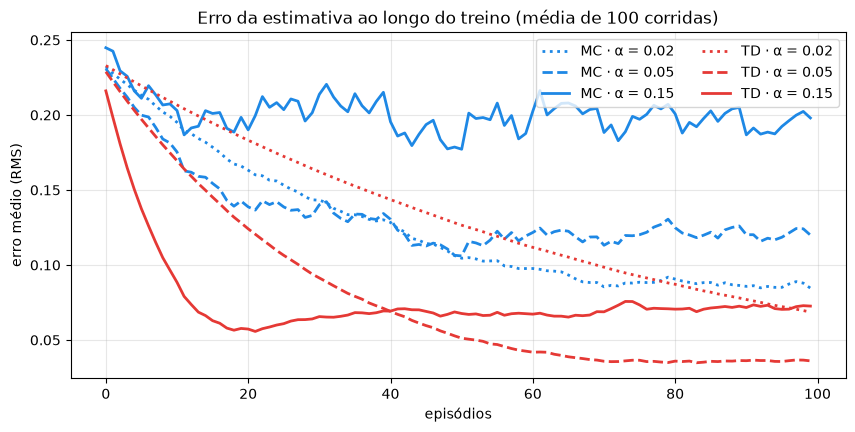

método     α  erro após 10 ep.  erro após 100 ep.
MC      0.02             0.199              0.085
MC      0.05             0.181              0.120
MC      0.15             0.207              0.198
TD      0.02             0.209              0.069
TD      0.05             0.175              0.036
TD      0.15             0.097              0.073


In [5]:
def curva_de_erro(metodo, alfa, n_corridas=100, n_episodios=100):
    erros = np.zeros(n_episodios)
    for corrida in range(n_corridas):
        rng = np.random.default_rng(corrida)
        V = np.full(5, .5)
        for ep in range(n_episodios):
            metodo(V, episodio(rng), alfa)
            erros[ep] += np.sqrt(np.mean((V - V_REAL) ** 2))
    return erros / n_corridas


fig, ax = plt.subplots(figsize=(10, 4.5))
resumo = []
for metodo, nome, cor in [(monte_carlo, 'MC', '#1E88E5'), (td0, 'TD', '#E53935')]:
    for alfa, estilo in [(.02, ':'), (.05, '--'), (.15, '-')]:
        erro = curva_de_erro(metodo, alfa)
        ax.plot(erro, estilo, color=cor, lw=2, label=f'{nome} · α = {alfa}')
        resumo.append((nome, alfa, erro[9], erro[-1]))
ax.set_xlabel('episódios'); ax.set_ylabel('erro médio (RMS)')
ax.set_title('Erro da estimativa ao longo do treino (média de 100 corridas)')
ax.grid(alpha=.3); ax.legend(ncol=2)
plt.show()

print(f"{'método':6s} {'α':>5s} {'erro após 10 ep.':>17s} {'erro após 100 ep.':>18s}")
for nome, alfa, e10, e100 in resumo:
    print(f"{nome:6s} {alfa:5.2f} {e10:17.3f} {e100:18.3f}")

**O que observar**
- Neste problema, o **TD aprende mais rápido e termina com menos erro** que o Monte Carlo, para o mesmo α — o resultado clássico de Sutton & Barto (exemplo 6.2).
- **α grande** aprende rápido no começo, mas a estimativa fica "tremendo" e o erro para de cair; **α pequeno** é estável, porém lento. É o mesmo trade-off que você viu no Q-Learning (slide 101).
- O TD tem uma vantagem que não aparece aqui: ele **não precisa que o episódio termine**. Um robô de armazém que trabalha sem parar nunca "chega ao fim" — só o TD consegue aprender nele.

## Para pensar

1. **Slide 80:** "MC: sem viés, mas variância alta". Onde você viu a variância alta na animação da seção 2?
2. O TD usa a **própria estimativa** como alvo. Se essa estimativa estiver errada, o alvo também está. Por que, mesmo assim, ele funciona?
3. **Ponte com o Q-Learning:** compare a regra do TD, $V(s) \leftarrow V(s) + \alpha[R + \gamma V(s') - V(s)]$, com a do Q-Learning do slide 91. O que mudou?
4. **Negócio:** num projeto de vendas que dura 6 meses, você esperaria o fim do projeto (MC) para avaliar as decisões da equipe ou ajustaria a cada reunião semanal (TD)? Que risco cada escolha traz?